# 📊 Análise de um Programa de Fidelidade

**Autora:** Bianca Bortoleto · Analista de BI

Este notebook conta a história de um programa de fidelidade de coalizão (10 parceiros de varejo) ao longo de 2024–2025,
respondendo a cinco perguntas de negócio:

1. **Como o programa está crescendo?** — base ativa, faturamento (GMV) e passivo de pontos
2. **Quem são os clientes que importam?** — segmentação RFM
3. **Os clientes ficam?** — retenção por coorte e por canal de aquisição
4. **As campanhas funcionam de verdade?** — teste A/B com grupo de controle, uplift e ROI
5. **Tem gente fraudando resgates?** — score de risco por regras e sua evolução

> ⚠️ **Dados 100% sintéticos**, gerados por `src/gerar_dados.py`. Nenhuma informação real de empresa ou cliente foi usada.
> Toda a lógica de negócio está em SQL (`sql/`) e roda em DuckDB via `src/pipeline.py`.

In [1]:
import sys, pathlib
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.ticker as mtick
from estilo import *

aplicar_estilo()
P = RAIZ / "data" / "processed"
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

kpis       = pd.read_csv(P / "mart_kpis_mensais.csv", parse_dates=["mes"])
rfm        = pd.read_csv(P / "mart_rfm_resumo.csv")
coortes    = pd.read_csv(P / "mart_coortes.csv", parse_dates=["mes_coorte"])
ret_canal  = pd.read_csv(P / "mart_retencao_canal.csv")
campanhas  = pd.read_csv(P / "mart_campanhas.csv", parse_dates=["data_inicio", "data_fim"])
fraude     = pd.read_csv(P / "mart_antifraude.csv")
aval       = pd.read_csv(P / "avaliacao_antifraude.csv")
parceiros  = pd.read_csv(P / "mart_parceiros.csv", parse_dates=["mes"])

## 1. Visão geral do programa

In [2]:
a24, a25 = kpis[kpis.mes.dt.year == 2024], kpis[kpis.mes.dt.year == 2025]
resumo = pd.DataFrame({
    "2024": [a24.gmv.sum(), a24.novos_clientes.sum(), a24.clientes_ativos.iloc[-1], a24.gmv.sum() / a24.transacoes.sum()],
    "2025": [a25.gmv.sum(), a25.novos_clientes.sum(), a25.clientes_ativos.iloc[-1], a25.gmv.sum() / a25.transacoes.sum()],
}, index=["GMV (R$)", "Novos cadastros", "Clientes ativos em dezembro", "Ticket médio (R$)"])
resumo["Var. %"] = (resumo["2025"] / resumo["2024"] - 1) * 100
resumo

,2024,2025,Var. %
GMV (R$),"18,397,798.66","37,272,799.52",102.59
Novos cadastros,"6,870.00","10,289.00",49.77
Clientes ativos em dezembro,"4,270.00","6,771.00",58.57
Ticket médio (R$),191.19,190.01,-0.62


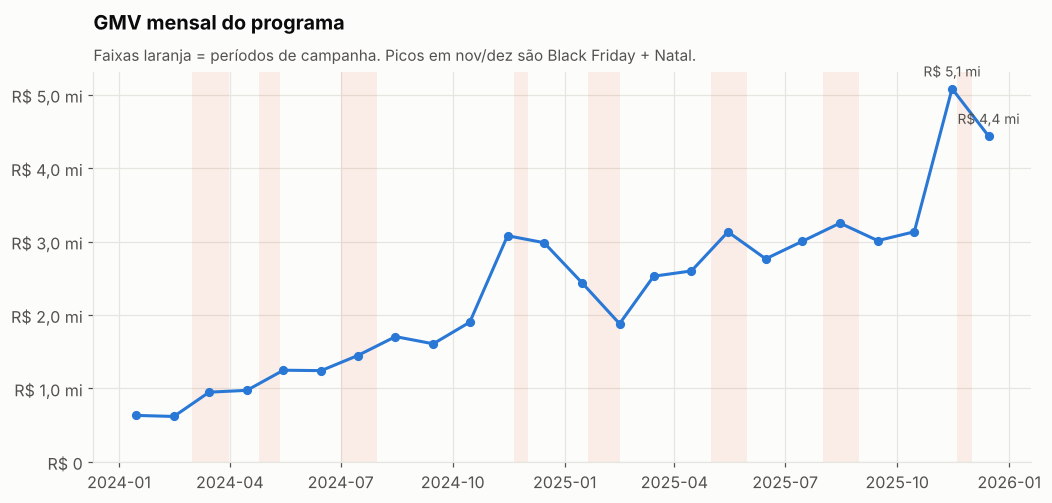

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for c in campanhas.itertuples():
    ax.axvspan(c.data_inicio, c.data_fim, color=LARANJA, alpha=0.10, lw=0)
ax.plot(kpis.mes + pd.Timedelta(days=14), kpis.gmv, color=AZUL, marker="o", ms=5)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(brl))
ax.set_ylim(0)
ax.set_title("GMV mensal do programa", pad=28)
subtitulo(ax, "Faixas laranja = períodos de campanha. Picos em nov/dez são Black Friday + Natal.")
for i in kpis.gmv.nlargest(2).index:
    ax.annotate(brl(kpis.gmv[i]), (kpis.mes[i] + pd.Timedelta(days=14), kpis.gmv[i]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=TEXTO_2)
fig.savefig(FIG / "01_gmv_mensal.png"); plt.show()

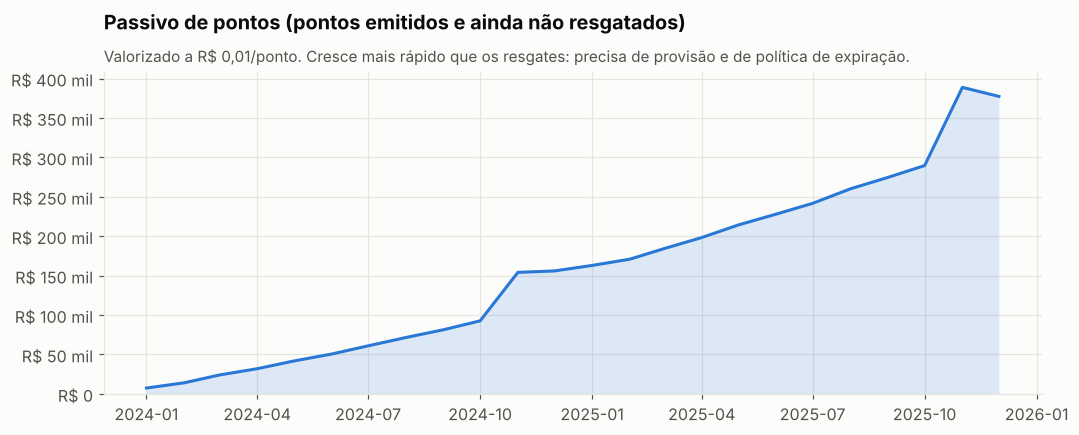

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(kpis.mes, kpis.passivo_reais, color=AZUL, alpha=0.15, lw=0)
ax.plot(kpis.mes, kpis.passivo_reais, color=AZUL)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(brl)); ax.set_ylim(0)
ax.set_title("Passivo de pontos (pontos emitidos e ainda não resgatados)", pad=28)
subtitulo(ax, "Valorizado a R$ 0,01/ponto. Cresce mais rápido que os resgates: precisa de provisão e de política de expiração.")
fig.savefig(FIG / "02_passivo_pontos.png"); plt.show()

**Leitura**
- O GMV **dobrou** de 2024 para 2025, puxado pelo crescimento da base ativa — o ticket médio ficou estável (~R$ 190).
  Ou seja: o programa cresce por **mais clientes comprando**, não por clientes gastando mais por compra.
- Novembro é o mês mais forte nos dois anos (Black Friday), com salto de **+60% sobre outubro**.
- O **passivo de pontos** só cresce. É dinheiro que o programa deve aos clientes — vale discutir regras de expiração
  e estimular resgates de clientes com saldo alto e baixa atividade.

## 2. Segmentação RFM — quem são os clientes que importam?

Cada cliente recebe uma nota de 1 a 5 em **Recência** (dias desde a última compra), **Frequência** e **Valor**
(últimos 12 meses), via `NTILE(5)` no SQL. As combinações viram segmentos acionáveis.

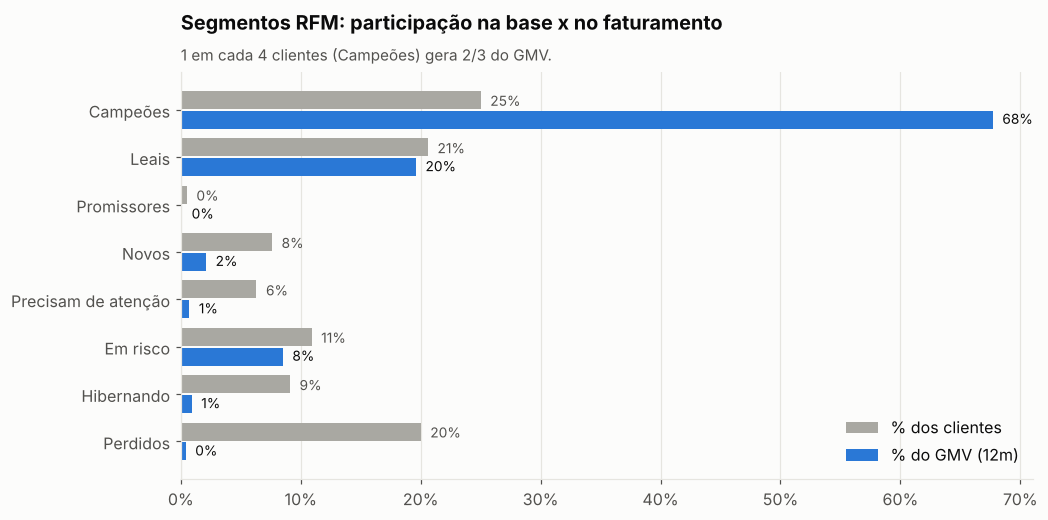

In [5]:
ordem = ["Campeões", "Leais", "Promissores", "Novos", "Precisam de atenção", "Em risco", "Hibernando", "Perdidos"]
r = rfm.set_index("segmento").loc[ordem].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
y = range(len(r)); h = 0.38
ax.barh([i + h/2 + 0.02 for i in y], r.pct_clientes, height=h, color=CINZA, label="% dos clientes")
ax.barh([i - h/2 - 0.02 for i in y], r.pct_gmv_12m, height=h, color=AZUL, label="% do GMV (12m)")
for i, (pc, pg) in enumerate(zip(r.pct_clientes, r.pct_gmv_12m)):
    ax.text(pc + 0.8, i + h/2, f"{pc:.0f}%", va="center", fontsize=9, color=TEXTO_2)
    ax.text(pg + 0.8, i - h/2, f"{pg:.0f}%", va="center", fontsize=9, color=TEXTO)
ax.set_yticks(list(y)); ax.set_yticklabels(r.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Segmentos RFM: participação na base x no faturamento", pad=28)
subtitulo(ax, "1 em cada 4 clientes (Campeões) gera 2/3 do GMV.")
fig.savefig(FIG / "03_rfm_segmentos.png"); plt.show()

In [6]:
rfm.set_index('segmento')

,clientes,pct_clientes,gmv_12m,pct_gmv_12m,recencia_media_dias,frequencia_media_12m,valor_medio_12m
segmento,,,,,,,
Campeões,4574,25.00,"25,237,484.96",67.70,10.00,28.80,"5,517.60"
Leais,3767,20.60,"7,301,402.62",19.60,47.00,10.70,"1,938.25"
Em risco,1993,10.90,"3,175,375.94",8.50,237.00,8.20,"1,593.26"
Novos,1394,7.60,"786,647.37",2.10,12.00,2.90,564.31
Hibernando,1663,9.10,"329,545.91",0.90,249.00,1.20,198.16
Precisam de atenção,1147,6.30,"272,335.15",0.70,81.00,1.20,237.43
Perdidos,3656,20.00,"135,532.09",0.40,495.00,0.10,37.07
Promissores,83,0.50,"34,475.48",0.10,23.00,2.00,415.37


**Leitura e ações sugeridas**
- **Campeões** (~25% da base) respondem por **~2/3 do GMV**. Prioridade: retenção e benefícios exclusivos — não precisam de desconto.
- **Em risco** é o segmento mais valioso para agir agora: compravam com frequência, mas sumiram há ~8 meses.
  Ainda carregam ~9% do GMV dos últimos 12 meses → candidatos a campanha de **reativação** (que, como veremos, é a de melhor ROI).
- **Perdidos** (20% da base) praticamente não geram receita: comunicação de baixo custo ou nenhuma.

## 3. Retenção por coorte — os clientes ficam?

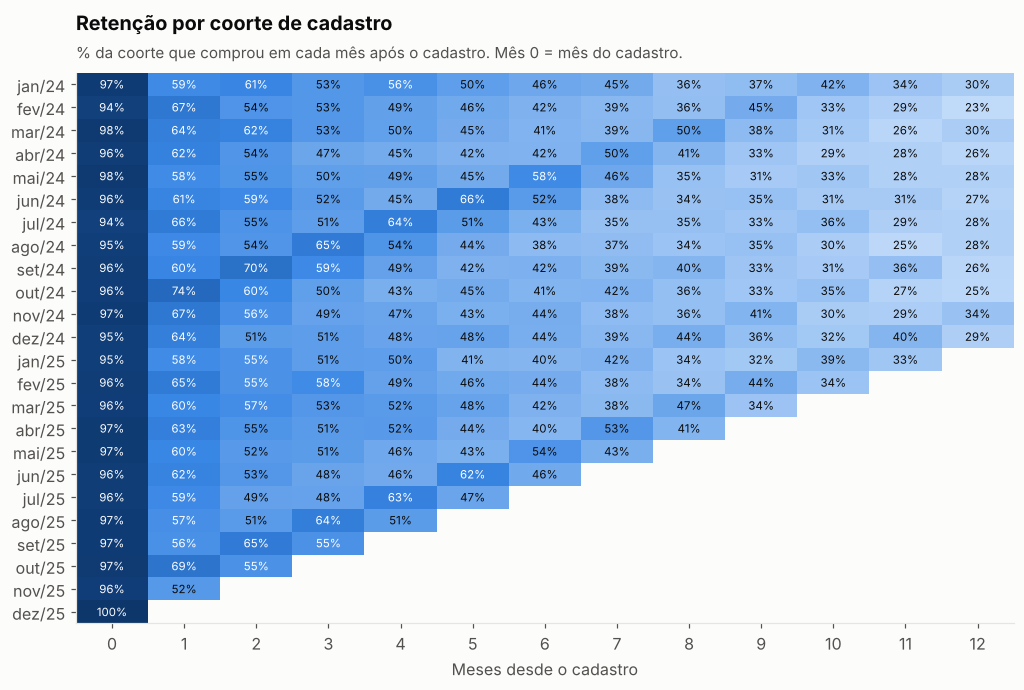

In [7]:
mat = coortes.pivot(index="mes_coorte", columns="mes_desde_cadastro", values="taxa_retencao")
mat = mat.loc[:, 0:12]
fig, ax = plt.subplots(figsize=(11, 6.5))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", SEQ_AZUL)
im = ax.imshow(mat.values, cmap=cmap, vmin=0.2, vmax=1.0, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.55 else TEXTO)
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); MESES = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
ax.set_yticklabels([f"{MESES[d.month-1]}/{d:%y}" for d in mat.index])
ax.set_xlabel("Meses desde o cadastro"); ax.grid(False)
ax.set_title("Retenção por coorte de cadastro", pad=28)
subtitulo(ax, "% da coorte que comprou em cada mês após o cadastro. Mês 0 = mês do cadastro.")
fig.savefig(FIG / "04_coortes.png"); plt.show()

Retenção média — mês 1: 62% | mês 3: 53% | mês 6: 44% | mês 12: 28%


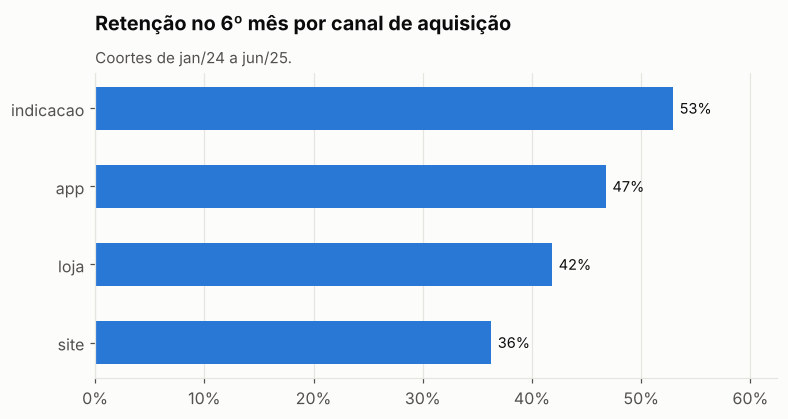

In [8]:
media = coortes.groupby("mes_desde_cadastro").taxa_retencao.mean()
print("Retenção média — mês 1: {:.0%} | mês 3: {:.0%} | mês 6: {:.0%} | mês 12: {:.0%}".format(media[1], media[3], media[6], media[12]))

fig, ax = plt.subplots(figsize=(8, 3.6))
rc = ret_canal.sort_values("retencao_m6")
ax.barh(rc.canal_aquisicao, rc.retencao_m6, color=AZUL, height=0.55)
for i, v in enumerate(rc.retencao_m6):
    ax.text(v + 0.006, i, f"{v:.0%}", va="center", fontsize=9.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.grid(axis="y", visible=False)
ax.set_xlim(0, rc.retencao_m6.max() * 1.18)
ax.set_title("Retenção no 6º mês por canal de aquisição", pad=28)
subtitulo(ax, "Coortes de jan/24 a jun/25.")
fig.savefig(FIG / "05_retencao_canal.png"); plt.show()

**Leitura**
- A maior queda acontece logo no **1º mês**: ~4 em cada 10 clientes não voltam depois da compra de cadastro.
  A régua de comunicação de onboarding (primeiros 30 dias) é onde está a maior alavanca.
- Clientes vindos de **indicação** retêm ~17 p.p. a mais no 6º mês do que os do **site** →
  argumento para investir em programa de *member-get-member*.

## 4. Campanhas — funcionam de verdade?

Toda campanha teve **20% do público sorteado como grupo de controle** (não recebeu a oferta).
Comparar tratamento x controle isola o efeito real da campanha do que aconteceria de qualquer jeito (sazonalidade, tendência).

- **Uplift** = conversão do tratamento − conversão do controle (compra na janela, no parceiro-alvo)
- **Significância**: teste z de duas proporções (p < 0,05)
- **ROI** = (GMV incremental × 20% de margem − custo) / custo · custo = pontos bônus (R$ 0,01/pt) + disparo

In [9]:
cols = ["nome_campanha", "n_trat", "n_ctrl", "conversao_tratamento", "conversao_controle",
        "uplift_pp", "p_valor", "significativo_95", "gmv_incremental", "custo_campanha", "roi"]
campanhas[cols].style.format({
    "conversao_tratamento": "{:.1%}", "conversao_controle": "{:.1%}", "uplift_pp": "{:+.1%}",
    "p_valor": "{:.3f}", "gmv_incremental": "R$ {:,.0f}", "custo_campanha": "R$ {:,.0f}", "roi": "{:.1f}x"
}).hide(axis="index")

nome_campanha,n_trat,n_ctrl,conversao_tratamento,conversao_controle,uplift_pp,p_valor,significativo_95,gmv_incremental,custo_campanha,roi
Pontos em Dobro – Supermercado,801,189,45.3%,33.3%,+12.0%,0.003,True,"R$ 17,417","R$ 1,174",2.0x
Dia das Mães – Moda,1259,304,14.2%,8.6%,+5.7%,0.009,True,"R$ 17,918",R$ 688,4.2x
Abasteça e Ganhe,1842,461,18.2%,15.0%,+3.3%,0.099,False,"R$ 25,846","R$ 1,002",4.2x
Black Friday Turbo,4634,1200,70.6%,47.1%,+23.5%,0.000,True,"R$ 796,438","R$ 45,433",2.5x
Volta às Aulas – Livraria,3236,809,5.7%,4.6%,+1.1%,0.201,False,"R$ 5,943",R$ 758,0.6x
Saúde em Dia – Farmácia,3956,985,24.9%,17.2%,+7.8%,0.000,True,"R$ 33,314","R$ 1,459",3.6x
Reativação – Sentimos sua falta,3434,904,14.6%,2.1%,+12.5%,0.000,True,"R$ 95,562","R$ 2,139",7.9x
Black Friday Turbo 2025,8478,2161,66.9%,44.2%,+22.7%,0.000,True,"R$ 1,307,630","R$ 73,751",2.5x


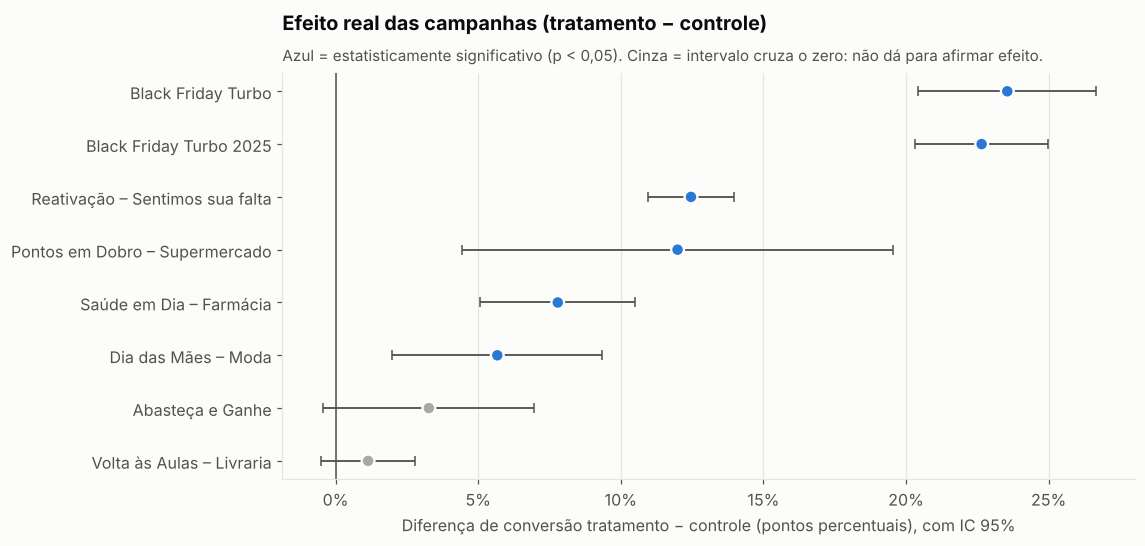

In [10]:
import numpy as np
c = campanhas.sort_values("uplift_pp").reset_index(drop=True)
# intervalo de confiança de 95% da diferença de proporções
ep = np.sqrt(c.conversao_tratamento*(1-c.conversao_tratamento)/c.n_trat + c.conversao_controle*(1-c.conversao_controle)/c.n_ctrl)
cores = [AZUL if s else CINZA for s in c.significativo_95]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.errorbar(c.uplift_pp, range(len(c)), xerr=1.96*ep, fmt="none", ecolor=TEXTO_2, elinewidth=1.2, capsize=3)
ax.scatter(c.uplift_pp, range(len(c)), color=cores, s=70, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(0, color=TEXTO_2, lw=1)
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.nome_campanha); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Diferença de conversão tratamento − controle (pontos percentuais), com IC 95%")
ax.set_title("Efeito real das campanhas (tratamento − controle)", pad=28)
subtitulo(ax, "Azul = estatisticamente significativo (p < 0,05). Cinza = intervalo cruza o zero: não dá para afirmar efeito.")
fig.savefig(FIG / "06_uplift_campanhas.png"); plt.show()

**Leitura**
- **Reativação** tem o **maior ROI (~8x)**: o grupo de controle praticamente não volta sozinho (2%), então quase tudo é incremental.
- **Black Friday** traz o maior GMV incremental em valor absoluto, mas o ROI é dos menores entre as campanhas que funcionaram (~2,5x):
  pontos em triplo custam caro e boa parte do público compraria de qualquer forma (controle já converte ~45%).
  → Testar pontos em **dobro** em vez de triplo.
- **"Abasteça e Ganhe"** mostra ROI aparente de ~4x, mas **não é significativa** (p ≈ 0,10): o resultado pode ser ruído.
  **"Volta às Aulas"** também não mostrou efeito. Olhar só o ROI, sem o teste, levaria a renovar campanhas que não comprovaram resultado.

## 5. Antifraude em resgates

Fraudes em programas de fidelidade costumam seguir um padrão: **várias contas novas, poucos aparelhos, acúmulo rápido de pontos
e resgate imediato**. O score (`sql/05_antifraude.sql`) soma regras simples e explicáveis — importante para o time de prevenção
conseguir justificar cada bloqueio.

Como os dados são sintéticos, existe um **gabarito** com as contas fraudulentas, o que permite medir **precisão** (dos alertados, quantos eram fraude)
e **recall** (das fraudes, quantas pegamos).

In [11]:
aval

,versao,verdadeiros_positivos,falsos_positivos,falsos_negativos,fraudadores_reais,precisao,recall
0,v1 (regras R1–R5),73.00,4.00,55.00,128,0.95,0.57
1,v2 (+ R6 cadastros em lote),121.00,4.00,7.00,128,0.97,0.94


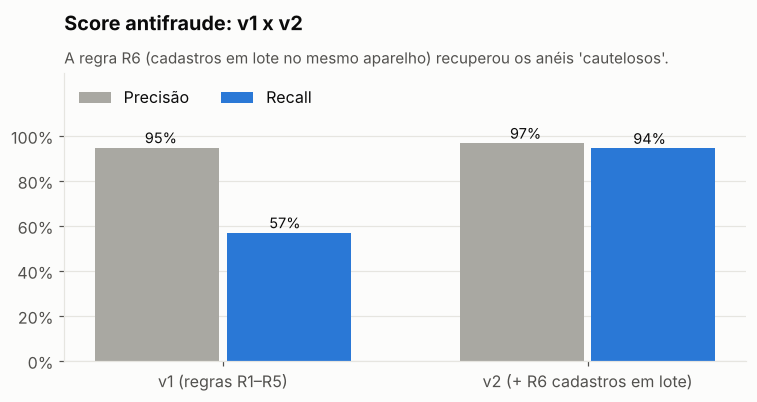

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(2); w = 0.34
ax.bar(x - w/2 - 0.01, aval.precisao, w, color=CINZA, label="Precisão")
ax.bar(x + w/2 + 0.01, aval.recall, w, color=AZUL, label="Recall")
for i in range(2):
    ax.text(i - w/2, aval.precisao[i] + 0.02, f"{aval.precisao[i]:.0%}", ha="center", fontsize=9.5)
    ax.text(i + w/2, aval.recall[i] + 0.02, f"{aval.recall[i]:.0%}", ha="center", fontsize=9.5)
ax.set_xticks(x); ax.set_xticklabels(aval.versao); ax.set_ylim(0, 1.28); ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.set_title("Score antifraude: v1 x v2", pad=28)
subtitulo(ax, "A regra R6 (cadastros em lote no mesmo aparelho) recuperou os anéis 'cautelosos'.")
fig.savefig(FIG / "07_antifraude.png"); plt.show()

In [13]:
# Os casos de maior risco para revisão manual
fraude[fraude.alerta].head(10)[["id_cliente", "id_dispositivo", "contas_no_dispositivo", "janela_cadastros_dias",
    "compras_72h", "dias_ate_1o_resgate", "pontos_resgatados", "score_risco"]]

,id_cliente,id_dispositivo,contas_no_dispositivo,janela_cadastros_dias,compras_72h,dias_ate_1o_resgate,pontos_resgatados,score_risco
0,20002,DVF842937320,20,2,12,0.71,"7,000.00",7
1,20020,DVF842937320,20,2,9,1.33,"7,000.00",7
2,20049,DVF187714384,11,2,10,1.21,"7,000.00",7
3,20054,DVF495774829,11,2,13,0.46,"7,000.00",7
4,20061,DVF187714384,11,2,10,1.08,"7,000.00",7
5,20106,DVF229460626,24,2,10,0.54,"7,000.00",7
6,20110,DVF229460626,24,2,8,0.29,"7,000.00",7
7,20015,DVF842937320,20,2,9,1.08,"6,000.00",7
8,20048,DVF495774829,11,2,9,0.92,"6,000.00",7
9,20056,DVF495774829,11,2,9,1.17,"6,000.00",7


**Leitura**
- A **v1** acertava quase tudo o que alertava (alta precisão), mas deixava passar ~40% das fraudes: anéis que espalham as contas
  em vários aparelhos e compram devagar não acionavam as regras de "dispositivo com 4+ contas" nem "rajada em 72h".
- Analisando os falsos negativos, surgiu a **R6**: *3+ contas cadastradas no mesmo aparelho em até 15 dias*.
  Ela captura os anéis cautelosos **sem** pegar famílias (2 contas) nem totens de autoatendimento em loja (cadastros espaçados no tempo).
- Resultado: recall de ~57% → **~95%**, mantendo a precisão acima de 95%.

## Conclusões e próximos passos

| Tema | Achado | Recomendação |
|---|---|---|
| Crescimento | GMV 2x em 2025, ticket estável | Crescimento vem de base ativa → proteger retenção |
| Passivo | Passivo de pontos cresce todo mês | Política de expiração + incentivo a resgate |
| RFM | 25% dos clientes = 2/3 do GMV | Benefícios não-monetários para Campeões; reativar "Em risco" |
| Retenção | Maior perda no 1º mês; indicação retém mais | Onboarding de 30 dias + member-get-member |
| Campanhas | Reativação ROI ~8x; 2 campanhas sem efeito comprovado | Sempre manter grupo de controle; testar BF com 2x pontos |
| Fraude | Regras v2 com ~95% de recall | Revisão manual dos alertas + bloqueio preventivo de resgate em contas novas |

**Próximos passos técnicos:** modelo de propensão a churn (para antecipar o "Em risco"), CLV por canal de aquisição
e detecção de anéis de fraude por grafo (contas ↔ dispositivos ↔ parceiros).